In [1]:
import numpy as np
import os

dataset_folder = "datasets"
table_test = np.load(os.path.join(dataset_folder, "ratings_test.npy"))
namesngenre = np.load(os.path.join(dataset_folder, "namesngenre.npy"))
table = np.load(os.path.join(dataset_folder, "ratings_train.npy"))

In [2]:
R = table.T                          # items × users
observed = ~np.isnan(R)
R0 = np.nan_to_num(R)

# --- 80/20 split of the observed cells ---
rng = np.random.default_rng(42)          # PLAY: seed (rerun with several seeds for mean ± std)
rows, cols = np.where(observed)      # positions of all known ratings
perm = rng.permutation(len(rows))
n_train = int(0.8 * len(rows))
tr, vl = perm[:n_train], perm[n_train:]

train_mask = np.zeros_like(observed)
train_mask[rows[tr], cols[tr]] = True
val_mask = np.zeros_like(observed)
val_mask[rows[vl], cols[vl]] = True

def rmse(mask, pred):
    err = mask * (R0 - pred)
    return np.sqrt((err ** 2).sum() / mask.sum())

## Neural Collaborative Filtering (He et al., 2017), adapted to explicit ratings

Version 1: the models as in the paper, with only the changes needed for ratings:

- **Output:** a_out is the identity instead of a sigmoid, since we predict a rating, not a probability. The output layer keeps its bias (as in the authors' Keras code), initialized at the mean training rating, so predictions start at the mean instead of 0.
- **Loss:** squared error on the observed ratings only, instead of log loss with negative sampling.
- **Evaluation:** RMSE on held-out ratings, with predictions clipped to [0.5, 5].

No regularization: no weight decay, no dropout, no user/item biases. Each model is trained for a fixed number of epochs, and the curves show train and validation RMSE after every epoch. The weights kept at the end are those of the epoch with the best validation RMSE.

In [3]:
import copy
import time
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

device = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 20


def to_triples(R_full, mask):
    """Observed cells of an items x users matrix as (user, item, rating) tensors."""
    items, users = np.nonzero(mask)
    return (torch.tensor(users, device=device),
            torch.tensor(items, device=device),
            torch.tensor(R_full[items, users], dtype=torch.float32, device=device))


train_t = to_triples(R0, train_mask)           # 80% of ratings_train
val_t = to_triples(R0, val_mask)               # 20% of ratings_train, used as validation
mu_train = float(R0[train_mask].mean())        # mean training rating
n_items, n_users = R0.shape


@torch.no_grad()
def rmse_t(model, data, batch_size=65536):
    """RMSE of the model on (user, item, rating) triples."""
    model.eval()
    u, i, r = data
    err = 0.0
    for s in range(0, len(r), batch_size):
        pred = model(u[s:s + batch_size], i[s:s + batch_size]).clamp(0.5, 5)
        err += ((pred - r[s:s + batch_size]) ** 2).sum().item()
    return np.sqrt(err / len(r))


def train(model, train_data, val_data=None, epochs=30, lr=1e-3, batch_size=256, optimizer="adam"):
    """Mini-batch training with squared error on observed ratings, no regularization.
    Records train (and validation) RMSE after every epoch. If val_data is given,
    the weights of the best validation epoch are restored at the end."""
    model.to(device)
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.Adam(params, lr=lr) if optimizer == "adam" else torch.optim.SGD(params, lr=lr)
    u, i, r = train_data
    history = {"train": [], "val": []}
    best, best_state = np.inf, None

    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(r), device=device)
        for s in range(0, len(r), batch_size):
            b = perm[s:s + batch_size]
            loss = ((model(u[b], i[b]) - r[b]) ** 2).mean()
            opt.zero_grad()
            loss.backward()
            opt.step()

        history["train"].append(rmse_t(model, train_data))
        if val_data is not None:
            v = rmse_t(model, val_data)
            history["val"].append(v)
            if v < best:
                best, best_state = v, copy.deepcopy(model.state_dict())

    if best_state is not None:
        model.load_state_dict(best_state)
    return history


def best_epoch(history):
    return int(np.argmin(history["val"])) + 1


TRAIN_COLOR, VAL_COLOR = "#2a78d6", "#eb6834"


def plot_history(histories):
    """One panel per model: train and validation RMSE per epoch, best epoch marked."""
    fig, axes = plt.subplots(1, len(histories), figsize=(4.5 * len(histories), 3.4),
                             sharey=True, squeeze=False)
    for ax, (name, h) in zip(axes[0], histories.items()):
        ep = np.arange(1, len(h["train"]) + 1)
        ax.plot(ep, h["train"], color=TRAIN_COLOR, lw=2, ls="--", label="train")
        ax.plot(ep, h["val"], color=VAL_COLOR, lw=2, label="validation")
        b = best_epoch(h)
        ax.plot(b, h["val"][b - 1], "o", color=VAL_COLOR, ms=8)
        ax.set_title(f"{name}\nbest validation {h['val'][b - 1]:.4f} at epoch {b}", fontsize=10)
        ax.set_xlabel("epoch")
        ax.grid(alpha=0.3)
    axes[0][0].set_ylabel("RMSE")
    axes[0][0].legend(frameon=False)
    plt.tight_layout()
    plt.show()


def summary(histories, times):
    for name, h in histories.items():
        b = best_epoch(h)
        print(f"{name:<20} best validation RMSE = {h['val'][b - 1]:.4f}  "
              f"(epoch {b}, train RMSE {h['train'][b - 1]:.4f}, {times[name]:.1f}s)")


train_kw = dict(epochs=30,                     # PLAY: number of epochs
                lr=1e-3,                       # PLAY: learning rate (authors' default: 0.001)
                batch_size=256)                # PLAY: batch size (authors' default: 256)

histories, times, models = {}, {}, {}


def run(name, model, **kw):
    """Train a model, store its history, time and weights (best validation epoch)."""
    t0 = time.time()
    histories[name] = train(model, train_t, val_t, **dict(train_kw, **kw))
    times[name] = time.time() - t0
    models[name] = model
    return model

### Baseline: standard matrix factorization

r̂_ui = p_u · q_i + b. This is MF (r̂ = I @ U.T), with a global offset b so that it starts at the mean rating like the other models, and trained the same way (mini-batches, Adam), so that the comparison only reflects the model.

In [4]:
class MF(nn.Module):
    """Standard MF: r̂ = p_u · q_i + b."""

    def __init__(self, n_users, n_items, mu, factors=8):
        super().__init__()
        self.P = nn.Embedding(n_users, factors)     # user vectors (your U)
        self.Q = nn.Embedding(n_items, factors)     # item vectors (your I)
        self.b = nn.Parameter(torch.tensor(mu))     # global offset, starts at the mean
        nn.init.normal_(self.P.weight, 0.0, 0.01)
        nn.init.normal_(self.Q.weight, 0.0, 0.01)

    def forward(self, u, i):
        return (self.P(u) * self.Q(i)).sum(dim=1) + self.b

### Part 1: GMF (eq. 8–9)

φ = p_u ⊙ q_i, then r̂ = hᵀφ + b. Compared with MF, the only difference is the learned vector h, which weighs each latent dimension (MF is GMF with h = 1).

In [5]:
class GMF(nn.Module):
    """Generalized Matrix Factorization: r̂ = hᵀ(p_u ⊙ q_i) + b."""

    def __init__(self, n_users, n_items, mu, factors=8):
        super().__init__()
        self.P = nn.Embedding(n_users, factors)
        self.Q = nn.Embedding(n_items, factors)
        self.h = nn.Linear(factors, 1)              # output layer: weights h and bias b
        nn.init.normal_(self.P.weight, 0.0, 0.01)   # paper: N(0, 0.01)
        nn.init.normal_(self.Q.weight, 0.0, 0.01)
        nn.init.constant_(self.h.bias, mu)

    def features(self, u, i):
        """φ_GMF: element-wise product of user and item vectors (linear kernel)."""
        return self.P(u) * self.Q(i)

    def forward(self, u, i):
        return self.h(self.features(u, i)).squeeze(1)

MF (baseline)        best validation RMSE = 0.9792  (epoch 14, train RMSE 0.7101, 0.8s)
GMF                  best validation RMSE = 0.9759  (epoch 8, train RMSE 0.7664, 0.9s)


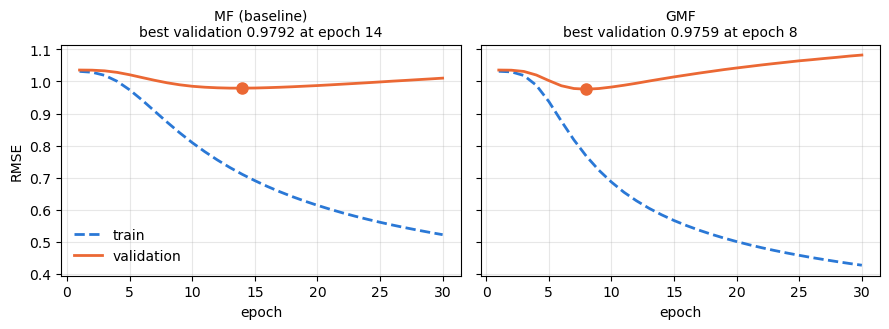

In [6]:
FACTORS = 8                                    # PLAY: latent factors for MF and GMF (paper: 8, 16, 32, 64)

train(MF(n_users, n_items, mu_train, FACTORS), train_t, epochs=1)   # warm-up: the first PyTorch run is slower

torch.manual_seed(SEED)
run("MF (baseline)", MF(n_users, n_items, mu_train, FACTORS))
torch.manual_seed(SEED)
run("GMF", GMF(n_users, n_items, mu_train, FACTORS))

subset = ["MF (baseline)", "GMF"]
summary({k: histories[k] for k in subset}, times)
plot_history({k: histories[k] for k in subset})

### Part 2: MLP (eq. 10)

z₁ = [p_u ; q_i], then ReLU layers, then r̂ = hᵀφ_L + b. `layers` follows the authors' code: the first number is the size of the concatenated embeddings (so each embedding has half of it), the following ones are the ReLU layers. The last one is the number of predictive factors.

In [7]:
class MLP(nn.Module):
    """Multi-Layer Perceptron: r̂ = hᵀ MLP([p_u ; q_i]) + b."""

    def __init__(self, n_users, n_items, mu, layers=(64, 32, 16, 8)):
        super().__init__()
        emb = layers[0] // 2                        # each embedding is half of the concatenation
        self.P = nn.Embedding(n_users, emb)
        self.Q = nn.Embedding(n_items, emb)
        tower = []
        for size_in, size_out in zip(layers[:-1], layers[1:]):
            tower += [nn.Linear(size_in, size_out), nn.ReLU()]
        self.tower = nn.Sequential(*tower)
        self.h = nn.Linear(layers[-1], 1)
        nn.init.normal_(self.P.weight, 0.0, 0.01)
        nn.init.normal_(self.Q.weight, 0.0, 0.01)
        nn.init.constant_(self.h.bias, mu)

    def features(self, u, i):
        """φ_MLP: concatenation passed through the ReLU layers (non-linear kernel)."""
        return self.tower(torch.cat([self.P(u), self.Q(i)], dim=1))

    def forward(self, u, i):
        return self.h(self.features(u, i)).squeeze(1)

MLP                  best validation RMSE = 0.8959  (epoch 4, train RMSE 0.7544, 1.7s)


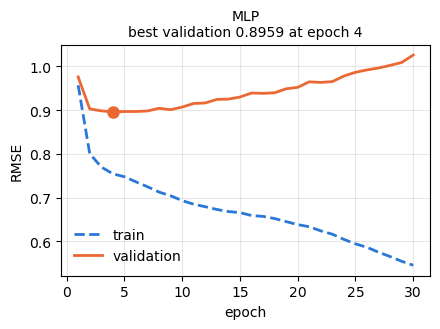

In [8]:
LAYERS = (64, 32, 16, 8)                       # PLAY: MLP layers (authors' default: 64, 32, 16, 8)

torch.manual_seed(SEED)
run("MLP", MLP(n_users, n_items, mu_train, LAYERS))

summary({"MLP": histories["MLP"]}, times)
plot_history({"MLP": histories["MLP"]})

### Part 3: NeuMF (eq. 12–13)

Separate GMF and MLP branches. Their outputs φ_GMF and φ_MLP are concatenated, and one output layer gives r̂ = hᵀ[φ_GMF ; φ_MLP] + b.

Two versions, as in the paper:
- **from scratch:** random initialization, trained with Adam;
- **pre-trained:** branches copied from the trained GMF and MLP, h = [α·h_GMF ; (1−α)·h_MLP] (eq. 13), then fine-tuned with plain SGD.

In [9]:
class NeuMF(nn.Module):
    """Neural Matrix Factorization: r̂ = hᵀ[φ_GMF ; φ_MLP] + b."""

    def __init__(self, gmf, mlp, mu, alpha=None):
        super().__init__()
        self.gmf, self.mlp = gmf, mlp               # the two branches (their own h is not used here)
        self.h = nn.Linear(gmf.h.in_features + mlp.h.in_features, 1)
        nn.init.constant_(self.h.bias, mu)
        if alpha is not None:                       # pre-trained branches: eq. 13
            with torch.no_grad():
                self.h.weight.copy_(torch.cat([alpha * gmf.h.weight,
                                               (1 - alpha) * mlp.h.weight], dim=1))
                self.h.bias.copy_(alpha * gmf.h.bias + (1 - alpha) * mlp.h.bias)

    def forward(self, u, i):
        phi = torch.cat([self.gmf.features(u, i), self.mlp.features(u, i)], dim=1)
        return self.h(phi).squeeze(1)

pre-trained NeuMF before fine-tuning: validation RMSE = 0.8984
NeuMF (scratch)      best validation RMSE = 0.8961  (epoch 3, train RMSE 0.7641, 2.5s)
NeuMF (pre-trained)  best validation RMSE = 0.8927  (epoch 1, train RMSE 0.6946, 1.2s)


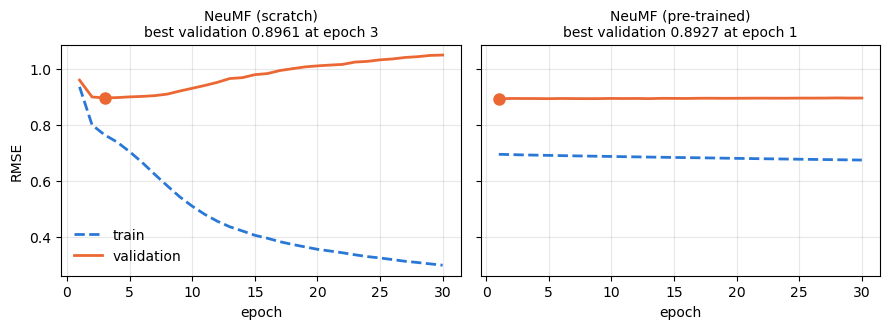

In [10]:
ALPHA = 0.5                                    # PLAY: GMF vs MLP weight in the pre-trained init (paper: 0.5)
FINETUNE = dict(optimizer="sgd", lr=1e-2)      # PLAY: paper fine-tunes with plain SGD; learning rate is our choice

torch.manual_seed(SEED)
scratch = NeuMF(GMF(n_users, n_items, mu_train, FACTORS),
                MLP(n_users, n_items, mu_train, LAYERS), mu_train)
run("NeuMF (scratch)", scratch)

pretrained = NeuMF(copy.deepcopy(models["GMF"]), copy.deepcopy(models["MLP"]), mu_train, alpha=ALPHA)
print(f"pre-trained NeuMF before fine-tuning: validation RMSE = {rmse_t(pretrained, val_t):.4f}")
torch.manual_seed(SEED)
run("NeuMF (pre-trained)", pretrained, **FINETUNE)

subset = ["NeuMF (scratch)", "NeuMF (pre-trained)"]
summary({k: histories[k] for k in subset}, times)
plot_history({k: histories[k] for k in subset})

### Validation summary

MF (baseline)        best validation RMSE = 0.9792  (epoch 14, train RMSE 0.7101, 0.8s)
GMF                  best validation RMSE = 0.9759  (epoch 8, train RMSE 0.7664, 0.9s)
MLP                  best validation RMSE = 0.8959  (epoch 4, train RMSE 0.7544, 1.7s)
NeuMF (scratch)      best validation RMSE = 0.8961  (epoch 3, train RMSE 0.7641, 2.5s)
NeuMF (pre-trained)  best validation RMSE = 0.8927  (epoch 1, train RMSE 0.6946, 1.2s)


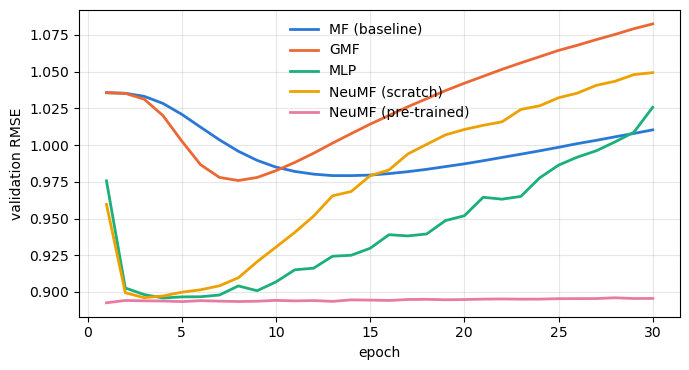

In [11]:
summary(histories, times)

colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
fig, ax = plt.subplots(figsize=(7, 3.8))
for (name, h), c in zip(histories.items(), colors):
    ax.plot(np.arange(1, len(h["val"]) + 1), h["val"], color=c, lw=2, label=name)
ax.set_xlabel("epoch")
ax.set_ylabel("validation RMSE")
ax.grid(alpha=0.3)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

### Final evaluation on ratings_test.npy

Each model is retrained on the full training file (100% of ratings_train) for the number of epochs that was best on validation, then scored once on the separate test file. For the pre-trained NeuMF, GMF and MLP are first retrained on the full file, then combined and fine-tuned.

In [12]:
full_t = to_triples(R0, observed)
mu_full = float(R0[observed].mean())
R_test = table_test.T
test_t = to_triples(np.nan_to_num(R_test), ~np.isnan(R_test))


def fit_full(model, name, **kw):
    """Retrain on the full training file for the best validation epoch count."""
    epochs = best_epoch(histories[name])
    train(model, full_t, None, **dict(train_kw, epochs=epochs, **kw))
    return model


final = {}
t0 = time.time()
torch.manual_seed(SEED)
final["MF (baseline)"] = fit_full(MF(n_users, n_items, mu_full, FACTORS), "MF (baseline)")
torch.manual_seed(SEED)
final["GMF"] = fit_full(GMF(n_users, n_items, mu_full, FACTORS), "GMF")
torch.manual_seed(SEED)
final["MLP"] = fit_full(MLP(n_users, n_items, mu_full, LAYERS), "MLP")
torch.manual_seed(SEED)
final["NeuMF (scratch)"] = fit_full(NeuMF(GMF(n_users, n_items, mu_full, FACTORS),
                                          MLP(n_users, n_items, mu_full, LAYERS), mu_full),
                                    "NeuMF (scratch)")
torch.manual_seed(SEED)
final["NeuMF (pre-trained)"] = fit_full(NeuMF(copy.deepcopy(final["GMF"]), copy.deepcopy(final["MLP"]),
                                              mu_full, alpha=ALPHA),
                                        "NeuMF (pre-trained)", **FINETUNE)

def n_params(model):
    """Number of trainable parameters."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"{'model':<20} {'validation RMSE':>16} {'test RMSE':>10} {'params':>10}")
for name, model in final.items():
    h = histories[name]
    print(f"{name:<20} {h['val'][best_epoch(h) - 1]:>16.4f} {rmse_t(model, test_t):>10.4f} "
          f"{n_params(model):>10,}")
print(f"(retraining all models: {time.time() - t0:.1f}s)")

model                 validation RMSE  test RMSE     params
MF (baseline)                  0.9792     0.9605     44,721
GMF                            0.9759     0.9637     44,729
MLP                            0.8959     0.8836    181,633
NeuMF (scratch)                0.8961     0.8830    226,379
NeuMF (pre-trained)            0.8927     0.8863    226,379
(retraining all models: 1.4s)


## Version 2: regularization

Same models (MF, GMF, MLP, NeuMF from scratch), with the regularization techniques added one at a time, so the effect of each is visible on its own:

1. **User and item biases:** r̂ = model(u, i) + b_u + b_i. The biases absorb generous users and popular movies, so the embeddings don't have to.
2. **L2 / weight decay:** shrinks the embeddings and weight matrices toward 0 at every step (AdamW). Rarely rated movies, whose vectors get few gradient updates, are pulled toward 0 the most. The global offset (the mean rating) and the layers' biases are not decayed, otherwise the prediction itself would be pulled toward 0.
3. **Dropout** in the MLP layers.
4. **Model size:** smaller MLP embeddings, and shared embeddings between the GMF and MLP branches of NeuMF.
5. **Early stopping:** stop when validation RMSE hasn't improved for `patience` epochs.

Each experiment changes one thing from the version 1 settings (`BASE`). Then `BEST` combines the settings you choose, and the last cell compares version 1 and version 2 on the test file. 

In [13]:
class WithBiases(nn.Module):
    """Adds a learned bias per user and per item to any model: r̂ = model(u, i) + b_u + b_i."""

    def __init__(self, model, n_users, n_items):
        super().__init__()
        self.model = model
        self.b_u = nn.Embedding(n_users, 1)
        self.b_i = nn.Embedding(n_items, 1)
        nn.init.zeros_(self.b_u.weight)
        nn.init.zeros_(self.b_i.weight)

    def forward(self, u, i):
        return self.model(u, i) + self.b_u(u).squeeze(1) + self.b_i(i).squeeze(1)


def add_dropout(mlp, p):
    """Inserts a Dropout layer after each ReLU of an MLP's tower."""
    if p > 0:
        layers = []
        for m in mlp.tower:
            layers.append(m)
            if isinstance(m, nn.ReLU):
                layers.append(nn.Dropout(p))
        mlp.tower = nn.Sequential(*layers)
    return mlp


def share_embeddings(gmf, mlp):
    """GMF and MLP branches use the same user and item tables (paper, eq. 11 idea)."""
    mlp.P, mlp.Q = gmf.P, gmf.Q
    return gmf, mlp


def n_params(model):
    """Number of trainable parameters (shared tables counted once)."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def make_model(name, mu, cfg):
    """Builds MF, GMF, MLP or NeuMF with the regularization settings in cfg."""
    f, layers = cfg["factors"], cfg["layers"]
    if name == "MF":
        model = MF(n_users, n_items, mu, f)
    elif name == "GMF":
        model = GMF(n_users, n_items, mu, f)
    elif name == "MLP":
        model = add_dropout(MLP(n_users, n_items, mu, layers), cfg["dropout"])
    elif name == "NeuMF":
        if cfg["share"]:
            assert layers[0] == 2 * f, "with shared embeddings, layers[0] must be 2 * factors"
        gmf = GMF(n_users, n_items, mu, f)
        mlp = add_dropout(MLP(n_users, n_items, mu, layers), cfg["dropout"])
        if cfg["share"]:
            gmf, mlp = share_embeddings(gmf, mlp)
        model = NeuMF(gmf, mlp, mu)
    return WithBiases(model, n_users, n_items) if cfg["biases"] else model


def train_reg(model, train_data, val_data=None, epochs=30, lr=1e-3, batch_size=256,
              weight_decay=0.0, patience=None):
    """Same training as version 1, with weight decay (AdamW) and optional early stopping.
    With weight_decay=0 and patience=None, it is identical to train()."""
    model.to(device)
    # decay embeddings and weight matrices, not the global offset or the layers' biases
    decay = [p for p in model.parameters() if p.requires_grad and p.dim() >= 2]
    no_decay = [p for p in model.parameters() if p.requires_grad and p.dim() < 2]
    opt = torch.optim.AdamW([{"params": decay, "weight_decay": weight_decay},
                             {"params": no_decay, "weight_decay": 0.0}], lr=lr)
    u, i, r = train_data
    history = {"train": [], "val": []}
    best, best_state, bad = np.inf, None, 0

    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(r), device=device)
        for s in range(0, len(r), batch_size):
            b = perm[s:s + batch_size]
            loss = ((model(u[b], i[b]) - r[b]) ** 2).mean()
            opt.zero_grad()
            loss.backward()
            opt.step()

        history["train"].append(rmse_t(model, train_data))
        if val_data is not None:
            v = rmse_t(model, val_data)
            history["val"].append(v)
            if v < best:
                best, best_state, bad = v, copy.deepcopy(model.state_dict()), 0
            else:
                bad += 1
                if patience is not None and bad >= patience:
                    break

    if best_state is not None:
        model.load_state_dict(best_state)
    return history


BASE = dict(biases=False,                      # version 1 settings: no regularization
            weight_decay=0.0,
            dropout=0.0,
            share=False,
            factors=FACTORS,
            layers=LAYERS,
            patience=None)


def fit(name, cfg, train_data=None, val_data=None, mu=None, epochs=None):
    """Builds and trains one model with config cfg. Returns (model, history, seconds)."""
    torch.manual_seed(SEED)
    model = make_model(name, mu_train if mu is None else mu, cfg)
    t0 = time.time()
    h = train_reg(model, train_t if train_data is None else train_data,
                  val_t if val_data is None and train_data is None else val_data,
                  epochs=train_kw["epochs"] if epochs is None else epochs,
                  lr=train_kw["lr"], batch_size=train_kw["batch_size"],
                  weight_decay=cfg["weight_decay"], patience=cfg["patience"])
    return model, h, time.time() - t0


def experiment(names, key, values):
    """Varies one setting of BASE, prints best validation RMSE and plots validation curves."""
    colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
    fig, axes = plt.subplots(1, len(names), figsize=(4.5 * len(names), 3.4), sharey=True, squeeze=False)
    for ax, name in zip(axes[0], names):
        for v, c in zip(values, colors):
            model, h, sec = fit(name, dict(BASE, **{key: v}))
            b = best_epoch(h)
            print(f"{name:<6} {key}={str(v):<16} best validation RMSE = {h['val'][b - 1]:.4f} "
                  f"(epoch {b}, {n_params(model):,} params, {sec:.1f}s)")
            ax.plot(np.arange(1, len(h["val"]) + 1), h["val"], color=c, lw=2, label=f"{key}={v}")
        ax.set_title(name)
        ax.set_xlabel("epoch")
        ax.grid(alpha=0.3)
    axes[0][0].set_ylabel("validation RMSE")
    axes[0][0].legend(frameon=False, fontsize=9)
    plt.tight_layout()
    plt.show()

### Experiment 1: user and item biases

MF     biases=False            best validation RMSE = 0.9792 (epoch 14, 44,721 params, 0.8s)
MF     biases=True             best validation RMSE = 0.9159 (epoch 11, 50,311 params, 1.1s)
GMF    biases=False            best validation RMSE = 0.9759 (epoch 8, 44,729 params, 0.9s)
GMF    biases=True             best validation RMSE = 0.9326 (epoch 8, 50,319 params, 1.2s)
MLP    biases=False            best validation RMSE = 0.8959 (epoch 4, 181,633 params, 1.6s)
MLP    biases=True             best validation RMSE = 0.8963 (epoch 4, 187,223 params, 2.0s)
NeuMF  biases=False            best validation RMSE = 0.8961 (epoch 3, 226,379 params, 2.3s)
NeuMF  biases=True             best validation RMSE = 0.8981 (epoch 3, 231,969 params, 2.6s)


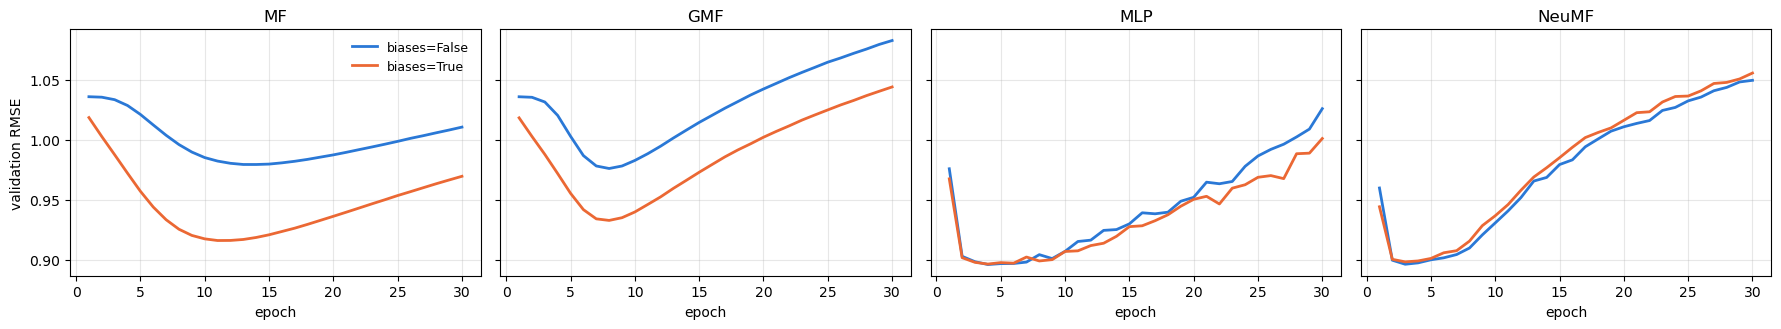

In [14]:
experiment(["MF", "GMF", "MLP", "NeuMF"], "biases", [False, True])

Biases

What changes. Without biases, MF predicts r̂ = μ + p_u·q_i. With biases, r̂ = μ + b_u + b_i + p_u·q_i.

Why it helps. Most of what’s predictable in ratings is not “taste matching” but two simple effects:

some users rate everything high, others everything low (b_u),
some movies are liked by almost everyone, others by almost no one (b_i).

Without biases, the model still has to capture these effects, and the only place it can put them is the embeddings. But a product p_u·q_i is a bad tool for an additive effect like “this movie is +0.6 for everyone”. To fake it, the model has to spend one or more dimensions on it (e.g. all users have a constant value in dimension 1, and q_i stores the movie’s popularity there). That’s clumsy and needs many updates to get right. Meanwhile the remaining dimensions, which are fitted on the training ratings of each user, end up mixing popularity, generosity and noise.

With biases, each effect gets one dedicated number that is learned from all of a user’s or movie’s ratings. One number estimated from many ratings is very stable (low variance). The embeddings then only have to explain what’s left: the actual taste interactions. That’s why it’s better on validation.

To be precise for the report: biases are not regularization in the strict sense, since they add parameters (44,721 → 50,311). They help because they give the model the right structure for the strongest signal in the data, so the embeddings don’t misuse their capacity on it. Bell & Koren’s global effects are the same idea.


A big gain for MF and GMF, nothing for MLP. That’s not a coincidence: the MLP’s first layer is linear on the concatenation [p_u ; q_i], so it computes W₁p_u + W₂q_i, which is a user term plus an item term. The MLP can already represent additive effects on its own, so separate biases add nothing. MF and GMF only have a product, so they can’t.

### Experiment 2: L2 regularization (weight decay)

With AdamW, each step multiplies the weights by (1 − lr × weight_decay), so with lr = 0.001 useful values are much larger than for a classic L2 penalty.

MF     weight_decay=0.0              best validation RMSE = 0.9792 (epoch 14, 44,721 params, 0.8s)
MF     weight_decay=0.1              best validation RMSE = 0.9761 (epoch 15, 44,721 params, 0.9s)
MF     weight_decay=1.0              best validation RMSE = 0.9742 (epoch 30, 44,721 params, 0.9s)
MF     weight_decay=10.0             best validation RMSE = 1.0328 (epoch 5, 44,721 params, 0.8s)
GMF    weight_decay=0.0              best validation RMSE = 0.9759 (epoch 8, 44,729 params, 0.8s)
GMF    weight_decay=0.1              best validation RMSE = 0.9750 (epoch 8, 44,729 params, 0.9s)
GMF    weight_decay=1.0              best validation RMSE = 0.9743 (epoch 18, 44,729 params, 0.9s)
GMF    weight_decay=10.0             best validation RMSE = 1.0349 (epoch 4, 44,729 params, 0.9s)
MLP    weight_decay=0.0              best validation RMSE = 0.8959 (epoch 4, 181,633 params, 1.7s)
MLP    weight_decay=0.1              best validation RMSE = 0.8949 (epoch 4, 181,633 params, 1.9s)
MLP    weight_

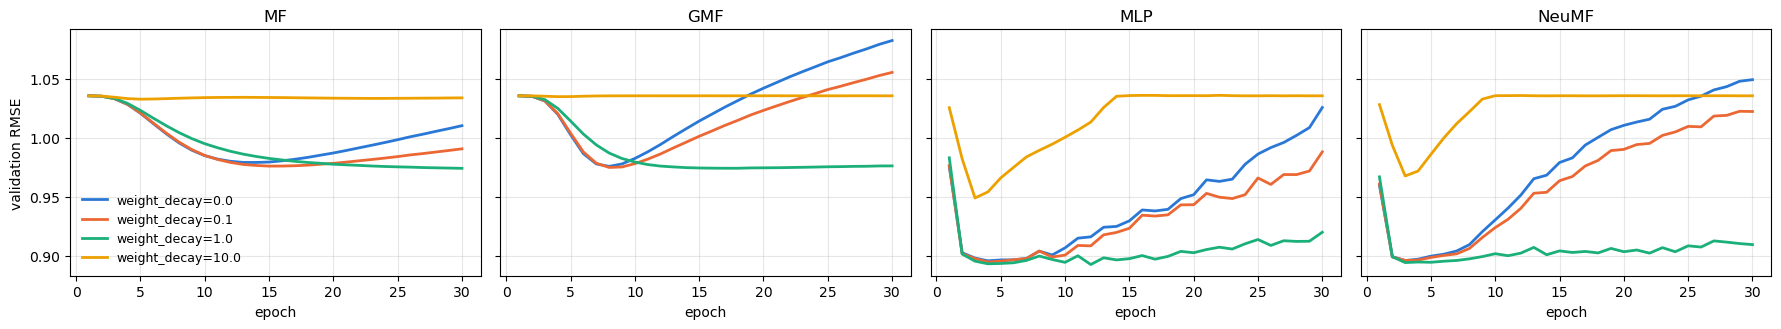

In [15]:
WD_VALUES = [0.0, 0.1, 1.0, 10.0]               # PLAY: weight decay values to compare

experiment(["MF", "GMF", "MLP", "NeuMF"], "weight_decay", WD_VALUES)

What it does. With AdamW, at each step, every decayed weight is multiplied by (1 − lr × wd) on top of the normal gradient update. With lr = 0.001 and wd = 1, that’s ×0.999 per step. It’s a constant pull toward 0, and the gradient has to fight against it. It’s close to adding λ‖w‖² to the loss (classic L2), though not exactly the same with Adam.

Why it reduces overfitting, three ways:

Rare movies and users fall back on the average. A movie with 3 ratings gets very few gradient updates, so decay wins and its vector stays close to 0. Its prediction becomes μ + b_u + b_i, which is a safe guess. A movie with 300 ratings gets enough gradient to keep a meaningful vector. That’s the same shrinkage idea as n/(n+α) in Bell & Koren, but automatic. Without decay, a rare movie’s vector can grow to fit its 3 ratings exactly, noise included.
Large weights are needed to memorize. Fitting each training rating exactly requires large, very specific values. Keeping the weights small forces simpler, smoother solutions that capture the shared patterns and not the individual noise.
In MF specifically: p·q = (c·p)·(q/c) for any c, so many solutions give the same predictions. Weight decay picks the one with the smallest norms. Mathematically, this pushes toward low-rank solutions: few dimensions used strongly instead of many dimensions used weakly.

Results: wd = 1 gives a small gain everywhere (MF 0.9848 → 0.9798, GMF 0.9902 → 0.9788, MLP 0.8968 → 0.8918). wd = 10 is clearly worse (1.03 for MF): the pull is so strong that all vectors are squashed to ~0 and the model predicts close to the mean. That’s underfitting. We also see that wd delays overfitting: the best epoch goes from 13 to 30 for MF.

### Experiment 3: dropout in the MLP layers

Only the MLP tower has dropout, so this only affects MLP and NeuMF.

MLP    dropout=0.0              best validation RMSE = 0.8959 (epoch 4, 181,633 params, 1.6s)
MLP    dropout=0.2              best validation RMSE = 0.8958 (epoch 5, 181,633 params, 1.8s)
MLP    dropout=0.5              best validation RMSE = 0.8992 (epoch 10, 181,633 params, 1.9s)
NeuMF  dropout=0.0              best validation RMSE = 0.8961 (epoch 3, 226,379 params, 2.2s)
NeuMF  dropout=0.2              best validation RMSE = 0.8939 (epoch 4, 226,379 params, 2.5s)
NeuMF  dropout=0.5              best validation RMSE = 0.9042 (epoch 7, 226,379 params, 2.5s)


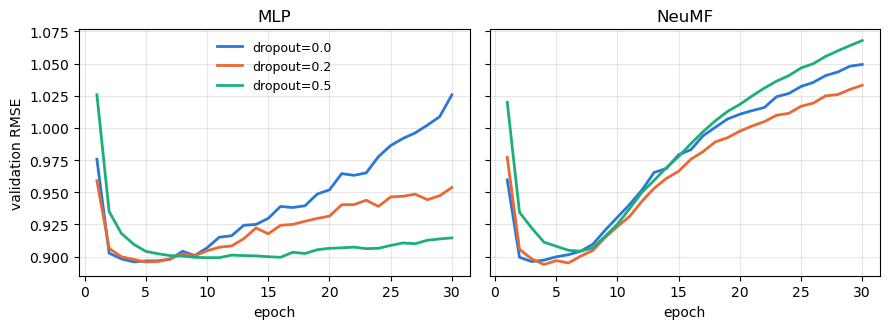

In [16]:
DROPOUT_VALUES = [0.0, 0.2, 0.5]                # PLAY: dropout rates to compare

experiment(["MLP", "NeuMF"], "dropout", DROPOUT_VALUES)

### Experiment 4: model size and shared embeddings

The number of parameters is printed for each model: almost all of them are in the embedding tables.

- **Smaller MLP:** `layers=(16, 8)` gives MLP embeddings of 8 per side (instead of 32) and a single ReLU layer.
- **Shared embeddings (NeuMF only):** GMF and MLP use the same user and item tables. This needs `layers[0] = 2 × factors`.

MLP    layers=(64, 32, 16, 8)  best validation RMSE = 0.8959 (epoch 4, 181,633 params, 1.6s)
MLP    layers=(16, 8)          best validation RMSE = 0.8962 (epoch 4, 44,865 params, 1.0s)
NeuMF  layers=(64, 32, 16, 8)  best validation RMSE = 0.8961 (epoch 3, 226,379 params, 2.3s)
NeuMF  layers=(16, 8)          best validation RMSE = 0.8921 (epoch 6, 89,611 params, 1.6s)


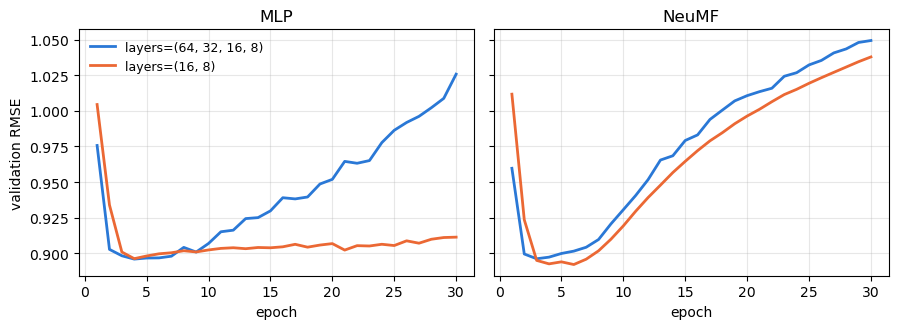

NeuMF  small, share=False  best validation RMSE = 0.8921 (epoch 6, 89,611 params, 1.6s)
NeuMF  small, share=True   best validation RMSE = 0.8935 (epoch 4, 44,891 params, 1.3s)


In [17]:
SMALL_LAYERS = (2 * FACTORS, FACTORS)           # PLAY: a smaller MLP (must start at 2 * factors to share)

experiment(["MLP", "NeuMF"], "layers", [LAYERS, SMALL_LAYERS])

torch.manual_seed(SEED)
for share in [False, True]:
    model, h, sec = fit("NeuMF", dict(BASE, layers=SMALL_LAYERS, share=share))
    b = best_epoch(h)
    print(f"NeuMF  small, share={share!s:<6} best validation RMSE = {h['val'][b - 1]:.4f} "
          f"(epoch {b}, {n_params(model):,} params, {sec:.1f}s)")

These differences are around 0.003–0.005, below the ~0.008 noise of the validation set. The honest conclusion is “the small models are as good with 2–5× fewer parameters”, not “clearly better”. When performance is equal, we choose the simpler model. It’s also faster, which counts for the platform’s running time.

Shared vs separate: sharing forces one vector per user to serve both the product (GMF) and the network (MLP). The paper argues separate is more flexible, since each branch may want different representations. Here, sharing loses nothing and halves the size, so with this little data the extra flexibility isn’t useful.

Constraints
layers[0] must be even, since it’s split into two halves (user, item). With 15, each side gets 7, the concatenation is 14, and the first Linear expects 15: crash.
With share=True: layers[0] = 2 × factors, because the MLP must receive vectors of the same size as GMF’s (the assert in make_model).
Each layer’s size must match the next one’s input. The code guarantees this by building the tower from consecutive pairs.
GMF: users and items must have the same size, because of the element-wise product. The MLP doesn’t have this constraint mathematically (concatenation works with any sizes), but the code uses layers[0]//2 for both.
Halving each layer (64→32→16→8) is the paper’s convention, not a rule. (32, 32, 8) works too.

### Version 2: all chosen settings together

Set `BEST` from the experiments above. Early stopping is added here: training stops when validation hasn't improved for `patience` epochs.

model     v1 validation  v2 validation  v2 epoch     params
MF               0.9792         0.9142        80     50,311
GMF              0.9759         0.9166        73     50,319
MLP              0.8959         0.8909        15     50,455
NeuMF            0.8961         0.8875         8     95,201


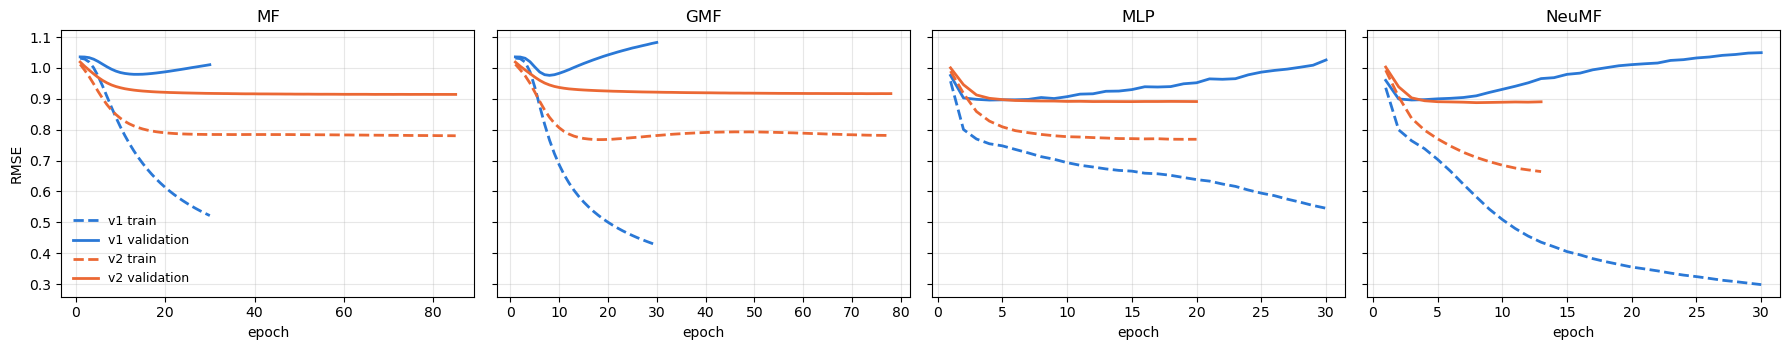

In [18]:
BEST = dict(biases=True,                        # PLAY: from experiment 1
            weight_decay=1.0,                   # PLAY: from experiment 2
            dropout=0.2,                        # PLAY: from experiment 3
            share=False,                        # PLAY: from experiment 4
            factors=FACTORS,
            layers=SMALL_LAYERS,                      # PLAY: from experiment 4
            patience=5)                         # PLAY: early stopping (None = always run all epochs)
V2_EPOCHS = 150                                  # PLAY: max epochs (early stopping usually ends sooner)

V1_NAMES = {"MF": "MF (baseline)", "GMF": "GMF", "MLP": "MLP", "NeuMF": "NeuMF (scratch)"}
histories_v2, models_v2, times_v2 = {}, {}, {}
for name in V1_NAMES:
    models_v2[name], histories_v2[name], times_v2[name] = fit(name, BEST, epochs=V2_EPOCHS)

print(f"{'model':<8} {'v1 validation':>14} {'v2 validation':>14} {'v2 epoch':>9} {'params':>10}")
for name, v1 in V1_NAMES.items():
    h1, h2 = histories[v1], histories_v2[name]
    print(f"{name:<8} {h1['val'][best_epoch(h1) - 1]:>14.4f} {h2['val'][best_epoch(h2) - 1]:>14.4f} "
          f"{best_epoch(h2):>9} {n_params(models_v2[name]):>10,}")

# train/validation curves, version 1 vs version 2
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6), sharey=True)
for ax, (name, v1) in zip(axes, V1_NAMES.items()):
    for h, c, label in [(histories[v1], "#2a78d6", "v1"), (histories_v2[name], "#eb6834", "v2")]:
        ep = np.arange(1, len(h["train"]) + 1)
        ax.plot(ep, h["train"], color=c, lw=2, ls="--", label=f"{label} train")
        ax.plot(ep, h["val"], color=c, lw=2, label=f"{label} validation")
    ax.set_title(name)
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("RMSE")
axes[0].legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

### Final evaluation on ratings_test.npy: version 1 vs version 2

Version 2 models are retrained on the full training file for their best validation epoch count (no early stopping, since there is no validation set any more), then scored once on the test file.

In [19]:
cfg_full = dict(BEST, patience=None)
print(f"{'model':<8} {'v1 test RMSE':>13} {'v2 test RMSE':>13}")
for name, v1 in V1_NAMES.items():
    model, _, _ = fit(name, cfg_full, train_data=full_t, mu=mu_full,
                      epochs=best_epoch(histories_v2[name]))
    print(f"{name:<8} {rmse_t(final[v1], test_t):>13.4f} {rmse_t(model, test_t):>13.4f}")

model     v1 test RMSE  v2 test RMSE
MF              0.9605        0.9045
GMF             0.9637        0.9054
MLP             0.8836        0.8808
NeuMF           0.8830        0.8777


In [20]:
# Variance over seeds: validation (80/20 split) and test (retrained on all of ratings_train)
SEEDS = [20, 21, 22]                            # PLAY: seeds (same as ncf_search.py)

V1_NEUMF = dict(BASE, lr=train_kw["lr"], batch_size=train_kw["batch_size"])   # paper architecture, no regularization
FINAL = dict(biases=True,                       # best configuration of the grid search (ncf_search.py)
             weight_decay=0.0,
             dropout=0.5,
             share=True,
             factors=8,
             layers=(16, 8),
             patience=5,
             lr=3e-3,
             batch_size=256)


def evaluate_seeds(name, cfg, epochs, seeds=SEEDS):
    """For each seed: train on 80% (best validation epoch), then retrain on all of
    ratings_train for that many epochs and score once on ratings_test."""
    res = dict(val=[], test=[], epoch=[], history=[])
    for s in seeds:
        kw = dict(lr=cfg["lr"], batch_size=cfg["batch_size"], weight_decay=cfg["weight_decay"])
        torch.manual_seed(s)
        model = make_model(name, mu_train, cfg)
        h = train_reg(model, train_t, val_t, epochs=epochs, patience=cfg["patience"], **kw)
        b = best_epoch(h)

        torch.manual_seed(s)
        full = make_model(name, mu_full, cfg)
        train_reg(full, full_t, None, epochs=b, **kw)

        res["val"].append(h["val"][b - 1])
        res["test"].append(rmse_t(full, test_t))
        res["epoch"].append(b)
        res["history"].append(h)
    res["params"] = n_params(model)
    return res


compare = {"NeuMF v1 (paper)": evaluate_seeds("NeuMF", V1_NEUMF, train_kw["epochs"]),
           "NeuMF final": evaluate_seeds("NeuMF", FINAL, V2_EPOCHS)}

print(f"{'model':<18} {'validation RMSE':>17} {'test RMSE':>17} {'epochs':>7} {'params':>9}")
for name, r in compare.items():
    print(f"{name:<18} {np.mean(r['val']):>9.4f} ± {np.std(r['val']):.4f} "
          f"{np.mean(r['test']):>9.4f} ± {np.std(r['test']):.4f} "
          f"{np.mean(r['epoch']):>7.0f} {r['params']:>9,}")

model                validation RMSE         test RMSE  epochs    params
NeuMF v1 (paper)      0.8968 ± 0.0014    0.8832 ± 0.0010       4   226,379
NeuMF final           0.8848 ± 0.0008    0.8741 ± 0.0007       6    50,481


Baseline

In [21]:
# Baseline: PyTorch MF (r̂ = μ + b_u + b_i + p_u·q_i), same protocol and seeds as the NeuMF runs above
MF_BASELINE = dict(BEST, lr=train_kw["lr"], batch_size=train_kw["batch_size"])   # PLAY: V1_NEUMF = MF without biases or weight decay

compare = {"MF baseline": evaluate_seeds("MF", MF_BASELINE, V2_EPOCHS), **compare}   # baseline first in the table and plots

print(f"{'model':<18} {'validation RMSE':>17} {'test RMSE':>17} {'epochs':>7} {'params':>9}")
for name, r in compare.items():
    print(f"{name:<18} {np.mean(r['val']):>9.4f} ± {np.std(r['val']):.4f} "
          f"{np.mean(r['test']):>9.4f} ± {np.std(r['test']):.4f} "
          f"{np.mean(r['epoch']):>7.0f} {r['params']:>9,}")

model                validation RMSE         test RMSE  epochs    params
MF baseline           0.9165 ± 0.0017    0.9054 ± 0.0006     102    50,311
NeuMF v1 (paper)      0.8968 ± 0.0014    0.8832 ± 0.0010       4   226,379
NeuMF final           0.8848 ± 0.0008    0.8741 ± 0.0007       6    50,481


After hyperparameters tuning with `ncf_search.py` testing with the best found hyperparameters

The best found hyperparameters : 
- factors (f) = 8
- Layers archhitecture (l) = 16-8
- Dropout (d) = 0.5
- Weight Decay (wd) = 0.0
- Bias (b) = True
- Share embedding (s) = True
- Learning rate (lr) = 0.003
- Batch size (bs) = 256 

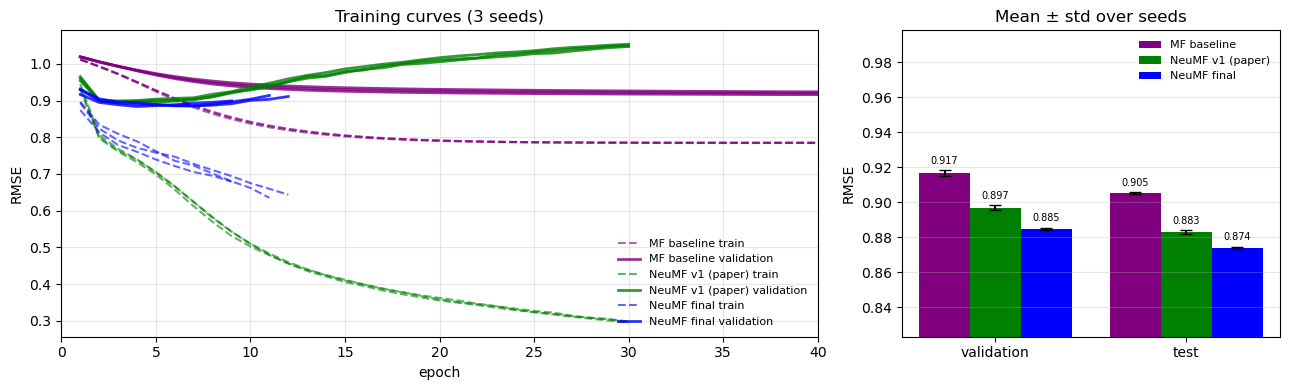

In [28]:
# Baseline, NeuMF v1 and final: training curves (all seeds) and validation / test RMSE (mean ± std over seeds)
colors = {"MF baseline": "purple", "NeuMF v1 (paper)": "green", "NeuMF final": "blue"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw=dict(width_ratios=[2, 1]))

for name, r in compare.items():
    for k, h in enumerate(r["history"]):
        ep = np.arange(1, len(h["train"]) + 1)
        ax1.plot(ep, h["train"], color=colors[name], lw=1.5, ls="--", alpha=0.6,
                 label=f"{name} train" if k == 0 else None)
        ax1.plot(ep, h["val"], color=colors[name], lw=2, alpha=0.8,
                 label=f"{name} validation" if k == 0 else None)
ax1.set_xlabel("epoch")
ax1.set_ylabel("RMSE")
ax1.set_title(f"Training curves ({len(SEEDS)} seeds)")
ax1.grid(alpha=0.3)
ax1.legend(frameon=False, fontsize=8)
ax1.set_xlim(0, 40)
x = np.arange(2)
w = 0.8 / len(compare)                           # bar width, so all models fit side by side
for k, (name, r) in enumerate(compare.items()):
    means = [np.mean(r["val"]), np.mean(r["test"])]
    stds = [np.std(r["val"]), np.std(r["test"])]
    bars = ax2.bar(x + (k - (len(compare) - 1) / 2) * w, means, w, yerr=stds, capsize=4,
                   color=colors[name], label=name)
    ax2.bar_label(bars, fmt="%.3f", fontsize=7, padding=3)
ax2.set_xticks(x, ["validation", "test"])
lo = min(min(r["val"] + r["test"]) for r in compare.values())
hi = max(max(r["val"] + r["test"]) for r in compare.values())
ax2.set_ylim(lo - 0.05, hi + 0.08)               # zoom on the differences (bars don't start at 0)
ax2.set_ylabel("RMSE")
ax2.set_title("Mean ± std over seeds")
ax2.grid(alpha=0.3, axis="y")
ax2.legend(frameon=False, fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()

validation RMSE = 0.8848 ± 0.0008  (best epoch 5, 50,481 params, 0.9s per seed)
test RMSE = 0.8735 ± 0.0005  (retrained on all of ratings_train for 5 epochs)

1. All top 10 use shared embeddings. That’s the clearest result. One set of user and item vectors for both branches beats separate ones. It fits the data: with ~3 ratings per movie, each extra vector per movie is mostly noise to learn. Sharing halves the embedding parameters, and each vector gets trained by both branches.

2. The smallest model wins. 8 of the top 10 are f = 8, layers (16, 8), with 50k parameters. Bigger models (f = 16, 95k) only appear at positions 7 and 10. This confirms experiment 4: capacity is not what’s missing here.

3. Dropout and weight decay substitute for each other. Dropout 0.5 dominates, and with it, weight decay doesn’t matter: 0, 0.3 and 1.0 all show up in the top 10. Once the model is regularized enough in one way, adding another kind brings nothing. Your notebook’s BEST (dropout 0.2 + wd 1.0) was a different point of the same balance.

4. Learning rate and batch size change the speed, not the result. lr 3e-3 with batch 256 reaches 0.8836 in 4 epochs. lr 1e-3 with batch 1024 reaches 0.8844 in 67 epochs. The final result is the same, but one is about 15× faster. Since the platform scores running time, take the fast one.

5. The whole top 10 is tied. The spread is 0.8836 → 0.8851 = 0.0015, far below the noise (~0.008 on validation, ~0.014 between reruns). The search doesn’t tell you which exact configuration is best. It tells you which region is good: small, shared, strongly regularized. That’s the honest conclusion for the report, and a good one. Run --top 10 --seeds 20 21 22 to confirm this region holds with several seeds.

6. Compared to the notebook’s v2: validation went from 0.8927 to 0.8836. Part of this gain is real (sharing, small size), and part may be selection luck from trying 960 configurations. The multi-seed rerun and the test set will tell you how much is real.

It’s better, but modestly. The gain over v2 is 0.004. The seed std is tiny (0.0005), so it’s not seed luck. There is still the noise from which ratings happen to be in the test set, but all models are scored on the same test ratings, so the comparison between them is fairer than the absolute values: slightly better, with 4.6× fewer parameters and training in 5 epochs. The size and speed gains are the solid part.
Validation and the search agree. 0.8848 ± 0.0008 with 3 seeds vs 0.8836 with one seed in the search: the single-seed value was only slightly lucky. Selection bias was small here.
The heavily regularized model is also more stable. The std across seeds is 0.0005, while the earlier GMF changed by 0.014 between two runs. Strong regularization reduces overfitting, and it also makes the result depend much less on the random initialization.
Test is lower than validation (0.8735 vs 0.8848). This is expected: the final model is retrained on 100% of ratings_train instead of 80%, so it has 25% more data.

In [24]:
import glob
import pandas as pd

df = pd.concat(pd.read_csv(f) for f in glob.glob("results/search1/results*.csv"))
for col in ["factors", "layers", "dropout", "weight_decay", "share", "lr", "batch_size"]:
    print(df.groupby(col)["val_rmse"].agg(["min", "median"]).round(4), "\n")

            min  median
factors                
4        0.8862  0.8929
8        0.8836  0.8929
16       0.8847  0.8920
32       0.8859  0.8938 

               min  median
layers                    
16-8        0.8836  0.8918
32-16       0.8847  0.8913
32-16-8     0.8850  0.8937
64-32-16-8  0.8879  0.8957 

            min  median
dropout                
0.0      0.8859  0.8929
0.2      0.8848  0.8923
0.5      0.8836  0.8938 

                 min  median
weight_decay                
0.0           0.8836  0.8928
0.3           0.8842  0.8925
1.0           0.8844  0.8921
3.0           0.8859  0.8964 

          min  median
share                
False  0.8859  0.8932
True   0.8836  0.8916 

          min  median
lr                   
0.001  0.8840  0.8926
0.003  0.8836  0.8931 

               min  median
batch_size                
256         0.8836  0.8922
1024        0.8842  0.8936 



setting	conclusion
share	True wins on min and median → the most robust finding
layers	bigger is worse: (64,32,16,8) is last on both. (32,16,8) is worse than (32,16), so depth doesn’t help
weight decay	3.0 is clearly too strong (median 0.8964); 0 to 1 are equivalent
factors	flat (differences of 0.001–0.002, within noise); 32 has the worst median
lr, batch size	no effect → choose the fastest
dropout	the interesting one, see below

Dropout 0.5 has the best min but the worst median. It gives the best result when combined with the right settings (small model, no weight decay), and hurts when added to other regularization. It’s a high-risk, high-reward value. 0.2 is the safe choice (best median). That’s the substitution between regularizers we discussed, now visible across all 960 runs.